# 07 · The balancer: Keeping what you *read* on target

The arranger makes every page **show** your slider mix. But people still **read** (click) their favorite topics more. It's like a buffet with equal amounts of every dish: you still fill your plate with your favorite.

The balancer fixes this in two parts:
- **Head start (feedforward):** before you scroll, use your past clicks to guess which topics you'll skip, and show a bit more of them from page 1.
- **Cruise control (PID feedback):** after every page, compare what you've clicked with your sliders and nudge the next page.

We can't test on real people, so we build **fake users** who click like real MIND users and let them scroll.

Everything here uses train (Nov 9–13) and validation (Nov 14) data only. 

In [6]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src.balancer import PIDBalancer, feedforward_mix
from src.data import BUCKETS, explode_impressions, load_behaviors, load_news, split_by_time
from src.finder import hourly_clicks, load_embeddings
from src.simulator import (
    ClickModel, World, auc, bucket_affinity, bucket_click_chance, click_features, shift_taste, simulate,
)
from src.two_tower import MODEL_PATH, TwoTower, device, history_matrix, popularity_table, user_vectors

dev = device()

In [7]:
news = load_news()
news_ids, vectors = load_embeddings()
index_of = {n: i for i, n in enumerate(news_ids)}
article_buckets = torch.as_tensor(
    news.bucket.map({b: i for i, b in enumerate(BUCKETS)}).fillna(-1).astype(int).values, device=dev
)

behaviors = load_behaviors()
train_b, val_b = split_by_time(behaviors)
row_of, hist = history_matrix(behaviors, index_of)
article_vectors = torch.as_tensor(vectors, device=dev)
history = torch.as_tensor(hist, device=dev)

model = TwoTower().to(dev)
model.load_state_dict(torch.load(MODEL_PATH))
model.eval()

with torch.no_grad():
    all_users = user_vectors(model, history, article_vectors)  # every user's vector
    all_items = model.items(article_vectors)                   # every article's vector
affinity = bucket_affinity(history, article_buckets, len(BUCKETS))  # each user's share of past clicks per bucket
hourly = hourly_clicks(behaviors)

## Part 1: Fake users who click like real people

A fake user's chance of clicking an article depends on:
1. **How good the article is for them:** the finder's score.
2. **How much they like its topic:** their share of past clicks in that bucket.
3. **A baseline click rate per bucket:** some topics simply get clicked more.

These are combined in a logistic regression **fitted on real Nov 14 clicks**. We fit on half the users and check on the other half.

In [8]:
def shown_rows(behaviors_part):
    """Every (user, article shown, clicked) row for bucketed articles, with click-model features."""
    rows = explode_impressions(behaviors_part)
    rows["item"] = rows.news_id.map(index_of)
    rows = rows[article_buckets.cpu().numpy()[rows.item.values] >= 0].reset_index(drop=True)
    rows["hour"] = rows.time.dt.floor("h")
    hour_row, table = popularity_table(hourly, rows.hour.unique(), index_of)
    with torch.no_grad():
        r = torch.as_tensor(rows.user_id.map(row_of).values, device=dev)
        it = torch.as_tensor(rows.item.values, device=dev)
        hr = torch.as_tensor(rows.hour.map(hour_row).values, device=dev)
        score = (all_users[r] * all_items[it]).sum(1) + 0.05 * torch.as_tensor(table, device=dev)[hr, it]
        features = click_features(score[:, None], article_buckets[it][:, None], affinity[r])[:, 0, :]
    return rows, features, torch.as_tensor(rows.clicked.values, device=dev)

val_rows, val_features, val_clicked = shown_rows(val_b)

rng = np.random.default_rng(0)
users = val_rows.user_id.unique()
fit_half = torch.as_tensor(val_rows.user_id.isin(set(rng.choice(users, len(users) // 2, replace=False))).values, device=dev)

check = ClickModel().fit(val_features[fit_half], val_clicked[fit_half])
held = val_rows[~fit_half.cpu().numpy()].copy()
held["predicted"] = check.probability(val_features[~fit_half]).cpu().numpy()
held["bucket"] = [BUCKETS[b] for b in article_buckets.cpu().numpy()[held.item.values]]

print(f"AUC on held-out users: {auc(held.predicted.values, held.clicked.values):.3f}  (0.5 = guessing; published MIND models ≈ 0.65–0.68)")
held.groupby("bucket")[["clicked", "predicted"]].mean().mul(100).round(2).rename(
    columns={"clicked": "real CTR %", "predicted": "predicted CTR %"}).reindex(BUCKETS)

AUC on held-out users: 0.672  (0.5 = guessing; published MIND models ≈ 0.65–0.68)


,real CTR %,predicted CTR %
bucket,,
News,4.17,4.19
Learn,3.45,3.53
Lifestyle,2.71,2.90
Entertain,4.74,4.75
Sports,3.72,3.71


In [9]:
# The simulator's "truth": fitted on all Nov 14 users
truth = ClickModel().fit(val_features, val_clicked)

# The feed's own click model for the head start: fitted on the TRAINING days, so it never sees the simulator's answers
train_rows, train_features, train_clicked = shown_rows(train_b.sample(frac=0.3, random_state=0))
feed_model = ClickModel().fit(train_features, train_clicked)
print(f"Feed's click model fitted on {len(train_rows):,} training rows (Nov 9–13)")

Feed's click model fitted on 1,393,388 training rows (Nov 9–13)


## Part 2: Scrolling sessions

Each fake user scrolls **30 pages of 20 articles**. Every page: the finder scores live articles from their current history, the arranger builds the page (strictness 0.5), the fake user clicks or skips each article, and clicks join their history. Articles never repeat.

Everyone asks for a **Balanced** mix (20% per topic). We measure the **gap** between what they've read so far and that target (0 = perfect). "Read" uses expected clicks (the sum of click chances) so the measurement isn't thrown off by luck in a handful of clicks.

**Mood shift:** Real people don't behave exactly like their history. We give each fake user a random shift in today's taste (spread 0.5) that the feed doesn't know about. This is where the PID earns its place.

**Four feeds:**

| Feed | What it does |
|---|---|
| Normal feed | Shows what you'd like most; ignores the sliders |
| Fixed quotas | Shows exactly the slider mix every page; ignores what you click |
| PID only | Starts at the slider mix, corrects from your clicks |
| **OwnFeed** | Head start from your history + gentle PID (kp 0.5, ki 0.05) |

In [10]:
val_shown = explode_impressions(val_b)
bucket_of = news.dropna(subset=["bucket"]).set_index("news_id").bucket.to_dict()
pool = np.array(sorted(set(val_shown.news_id) & set(bucket_of)))
pool_idx = torch.as_tensor([index_of[n] for n in pool], device=dev)
pool_buckets = np.array([bucket_of[n] for n in pool], dtype=object)
pool_bucket_idx = torch.as_tensor([BUCKETS.index(b) for b in pool_buckets], device=dev)

# Candidates for fake users: Nov 14 users with 10+ past clicks; session time = their first Nov 14 page view
first_visit = val_b.sort_values("time").drop_duplicates("user_id")
first_visit = first_visit[first_visit.user_id.map(lambda u: (hist[row_of[u]] >= 0).sum() >= 10)]
session_hour_row, session_table = popularity_table(hourly, first_visit.time.dt.floor("h").unique(), index_of)
session_popularity = torch.as_tensor(session_table, device=dev)

N_USERS, PAGES, MOOD = 2000, 30, 0.5
TARGET = [0.2, 0.2, 0.2, 0.2, 0.2]

def setup(seed):
    """A fresh sample of fake users: their world, starting history, today's taste and the head-start mix."""
    sample = first_visit.sample(N_USERS, random_state=seed)
    rows = torch.as_tensor(sample.user_id.map(row_of).values, device=dev)
    hours = torch.as_tensor(sample.time.dt.floor("h").map(session_hour_row).values, device=dev)
    world = World(model, article_vectors, pool_idx, pool_buckets, pool_bucket_idx,
                  session_popularity[hours][:, pool_idx], truth, BUCKETS)
    targets = np.tile(TARGET, (N_USERS, 1))
    head_start = feedforward_mix(targets, bucket_click_chance(world, history[rows], affinity[rows], feed_model))
    return world, history[rows], affinity[rows], targets, head_start

def feeds(head_start):
    return {
        "Normal feed": None,
        "Fixed quotas": lambda page, clicks, targets: targets,
        "PID only": PIDBalancer(kp=1.0, ki=0.1),
        "OwnFeed": PIDBalancer(kp=0.5, ki=0.05, start_mix=head_start),
    }

def gap_per_page(out, targets):
    """Average gap between the reading mix so far and the target, for each page."""
    read = out["expected"].cumsum(1)
    read_mix = read / read.sum(2, keepdims=True)
    return 0.5 * np.abs(read_mix - targets[:, None, :]).sum(2).mean(0)

In [11]:
SEEDS = [0, 1, 2, 3, 4]
gaps, summary = [], []
for seed in SEEDS:
    world, start_history, taste, targets, head_start = setup(seed)
    today = shift_taste(taste, MOOD, seed)
    for name, policy in feeds(head_start).items():
        out = simulate(world, start_history, today, targets, policy, pages=PAGES, seed=seed)
        gaps += [{"feed": name, "seed": seed, "page": p + 1, "gap": g} for p, g in enumerate(gap_per_page(out, targets))]
        favorite = taste.argmax(1).cpu().numpy()
        read_mix = out["expected"].sum(1) / out["expected"].sum((1, 2))[:, None]
        summary.append({
            "feed": name, "seed": seed,
            "gap_after_30_pages": gap_per_page(out, targets)[-1],
            "favorite_topic_share_of_reading_%": 100 * read_mix[np.arange(N_USERS), favorite].mean(),
            "click_rate_%": 100 * out["clicked"].sum() / out["shown"].sum(),
        })
gaps, summary = pd.DataFrame(gaps), pd.DataFrame(summary)
results = summary.groupby("feed", sort=False).agg(["mean", "std"]).drop(columns="seed").round(3)
results

gap_after_30_pages        favorite_topic_share_of_reading_%  \
                           mean    std                              mean   
feed                                                                       
Normal feed               0.291  0.003                         41.356998   
Fixed quotas              0.199  0.002                         34.110001   
PID only                  0.146  0.001                         25.781000   
OwnFeed                   0.109  0.001                         24.062000   

                    click_rate_%         
                std         mean    std  
feed                                     
Normal feed   0.456        3.781  0.032  
Fixed quotas  0.262        3.553  0.026  
PID only      0.110        3.114  0.020  
OwnFeed       0.095        3.026  0.028

## Chart 2: OwnFeed keeps what you read closest to your sliders

Lines are averages over 5 runs (each with a different sample of 2,000 fake users); shaded bands are ±2 standard errors.

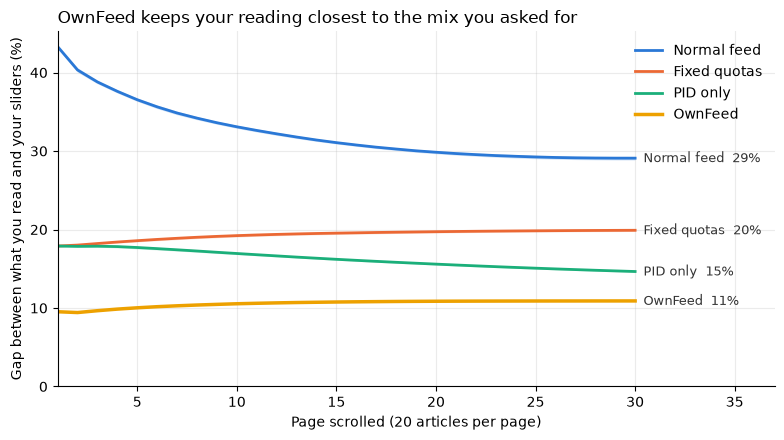

In [12]:
COLORS = {"Normal feed": "#2a78d6", "Fixed quotas": "#eb6834", "PID only": "#1baf7a", "OwnFeed": "#eda100"}

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, group in gaps.groupby("feed", sort=False):
    by_page = group.groupby("page").gap.agg(["mean", "std"]) * 100
    band = 2 * by_page["std"] / np.sqrt(len(SEEDS))
    ax.plot(by_page.index, by_page["mean"], color=COLORS[name], lw=2.5 if name == "OwnFeed" else 2, label=name)
    ax.fill_between(by_page.index, by_page["mean"] - band, by_page["mean"] + band, color=COLORS[name], alpha=0.2, lw=0)
    ax.annotate(f"{name}  {by_page['mean'].iloc[-1]:.0f}%", (PAGES, by_page["mean"].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color="#333333")

ax.set_xlabel("Page scrolled (20 articles per page)")
ax.set_ylabel("Gap between what you read and your sliders (%)")
ax.set_title("OwnFeed keeps your reading closest to the mix you asked for", loc="left", fontsize=12)
ax.set_xlim(1, PAGES + 7)
ax.set_ylim(0, None)
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig("../results/figures/chart2_reading_gap.png", dpi=150)
plt.show()

## Why keep the PID? 

It matters when today differs from your history

Same comparison (seed 0) for three levels of mood shift: none (users behave exactly like their history), some (0.5, used above) and big (1.0).

In [ ]:
world, start_history, taste, targets, head_start = setup(0)
mood_rows = []
for mood in [0.0, 0.5, 1.0]:
    today = shift_taste(taste, mood, 0)
    for name, policy in feeds(head_start).items():
        if name == "Normal feed":
            continue
        out = simulate(world, start_history, today, targets, policy, pages=PAGES, seed=0)
        mood_rows.append({"mood shift": mood, "feed": name, "gap_after_30_pages": gap_per_page(out, targets)[-1]})
    head_only = simulate(world, start_history, today, targets, lambda page, clicks, t: head_start, pages=PAGES, seed=0)
    mood_rows.append({"mood shift": mood, "feed": "Head start only (no PID)", "gap_after_30_pages": gap_per_page(head_only, targets)[-1]})

pd.DataFrame(mood_rows).pivot(index="feed", columns="mood shift", values="gap_after_30_pages").round(3)

mood shift,0.0,0.5,1.0
feed,,,
Fixed quotas,0.188,0.199,0.226
Head start only (no PID),0.095,0.116,0.162
OwnFeed,0.098,0.109,0.133
PID only,0.140,0.147,0.160


In [14]:
# Save results for the README
results.to_csv("../results/balancer_results.csv")
gaps.to_csv("../results/balancer_gap_by_page.csv", index=False)